# Phishing detection pipeline — layer by layer

Each section runs the code of one layer and keeps its output and metrics in this notebook.

| Layer | Role | Module |
|---|---|---|
| A. Blocklist | Instant block (PhishTank / OpenPhish / Phishing.Database) | `src/blocklist/` |
| B. Typosquatting | Brand impersonation (Damerau-Levenshtein + Jaro-Winkler) | `src/typosquatting/` |
| C. URL classifier | CNN/BiLSTM + XGBoost, URL + host features: clean / suspicious | `src/url_classifier/` |
| D. LLM + RAG | Final verdict for suspicious URLs | `src/llm_rag/` |

Switches: `RUN_TRAINING` re-trains Layer C (~1 h), `RUN_LLM` calls the paid OpenAI API.
When off, the notebook loads the metrics saved in `reports/`.

In [1]:
import json, sys, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for p in (ROOT / "src", ROOT / "src" / "llm_rag"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
pd.set_option("display.max_colwidth", 120)

RUN_TRAINING = False   # re-train Layer C (GPU, ~1 hour)
RUN_LLM = False        # call the OpenAI API (costs money)

def show_json(path):
    return json.loads((ROOT / path).read_text(encoding="utf-8"))

print("project root:", ROOT)

project root: E:\DACNTT\Temp


## 1. Dataset

Phishing: Phishing.Database, PhishTank, OpenPhish, PhiUSIIL. Clean: URLs crawled from
Tranco-ranked homepages + PhiUSIIL legit. Split 70/15/15 **by site** (one site never appears in
two splits). Build: `python src/data_collection/build_dataset.py`.

In [2]:
df = pd.read_csv(ROOT / "dataset/urls/urls_labeled.csv")
stats = show_json("dataset/urls/stats.json")
print("built at:", stats["built_at"], "| rows:", len(df), "| sites:", df.group.nunique())
display(pd.crosstab(df.split, df.label, margins=True))
display(pd.crosstab(df.source, df.label, margins=True))
print("dropped while cleaning:", stats["dropped"])

built at: 2026-10-07T16:21:15.398464+00:00 | rows: 537613 | sites: 360962


label,clean,phishing,All
split,,,
test,42351,39282,81633
train,193818,182803,376621
val,40578,38781,79359
All,276747,260866,537613


label,clean,phishing,All
source,,,
openphish,0,267,267
phishing_database,0,150643,150643
phishtank,0,35997,35997
phiusiil,133771,73959,207730
tranco_crawl,142976,0,142976
All,276747,260866,537613


dropped while cleaning: {'duplicate': 16474, 'unparsable_or_too_long': 104, 'phishing_bare_top10k_homepage': 8062, 'label_conflict': 70, 'phishing_bare_official_homepage': 24, 'clean_host_in_phishing_set': 406, 'over_site_cap': 91557}


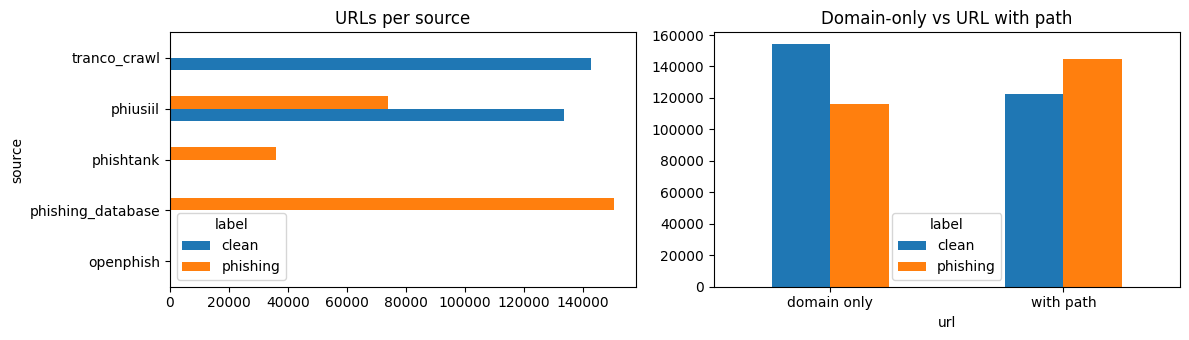

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
pd.crosstab(df.source, df.label).plot.barh(ax=ax[0], title="URLs per source")
bare = ~df.url.str.replace(r"^https?://", "", regex=True).str.rstrip("/").str.contains("/")
pd.crosstab(bare.map({True: "domain only", False: "with path"}), df.label).plot.bar(
    ax=ax[1], title="Domain-only vs URL with path", rot=0)
plt.tight_layout(); plt.show()

## 2. Layer A — blocklist

Monthly refresh (`src/blocklist/updater.py`). Matching: exact URL, path prefix, whole host
(never for popular/shared hosts), whole campaign domain (3–50 listed subdomains), and the same
rules on destinations hidden in redirect parameters.

In [4]:
from blocklist import lookup
from blocklist.updater import META_PATH, needs_refresh

print(json.dumps(json.loads(META_PATH.read_text()), indent=2))
print("needs refresh:", needs_refresh())
t0 = time.perf_counter(); lookup.reload(); n = lookup.size()
print(f"loaded {n:,} URLs in {time.perf_counter() - t0:.1f}s")

{
  "updated_at": "2026-10-07T12:56:12.275022+00:00",
  "sources": {
    "openphish": {
      "count": 291,
      "fetched_at": "2026-10-07T12:54:56.177144+00:00",
      "last_status": "ok"
    },
    "phishtank": {
      "count": 67846,
      "fetched_at": "2026-10-07T15:14:34.962583+00:00",
      "last_status": "ok"
    },
    "phishing_database": {
      "count": 770814,
      "fetched_at": "2026-10-07T12:56:05.342465+00:00",
      "last_status": "ok"
    }
  },
  "blockable_hosts": 279803,
  "abused_platforms": 839
}
needs refresh: False


loaded 837,485 URLs in 1.3s


In [5]:
import gzip
listed = gzip.open(ROOT / "data/blocklist/openphish.txt.gz", "rt").readline().strip()
campaign = next(l.strip()[2:] for l in gzip.open(ROOT / "data/blocklist/blockable_hosts.txt.gz", "rt")
                if l.startswith("*."))
examples = [
    "https://" + listed,                                   # exact URL
    "https://" + listed + "/deeper/login.php",             # path prefix
    f"https://brand-new-subdomain.{campaign}/x",           # campaign domain
    "https://www.google.com/url?q=https://" + listed,      # hidden redirect target
    "https://www.google.com/", "https://vercel.app/",      # popular / shared: never blocked whole
]
pd.DataFrame([{"url": u[:80], **{k: v for k, v in lookup.check_blocklist(u).items() if k != "name"}}
              for u in examples])

,url,flag,reason,latency_ms
0,https://0112532.com,True,URL nằm trong danh sách phishing công khai đã biết (OpenPhish/PhishTank/Phishing.Database).,0.115
1,https://0112532.com/deeper/login.php,True,URL nằm trong danh sách phishing công khai đã biết (OpenPhish/PhishTank/Phishing.Database).,0.063
2,https://brand-new-subdomain.000web.xyz/x,True,Tên miền 000web.xyz thuộc chiến dịch phishing đã biết (nhiều subdomain bị liệt kê).,143.838
3,https://www.google.com/url?q=https://0112532.com,True,URL chuyển hướng tới https://0112532.com — URL nằm trong danh sách phishing công khai đã biết (OpenPhish/PhishTank/P...,0.136
4,https://www.google.com/,False,Không có trong blocklist.,0.039
5,https://vercel.app/,False,Không có trong blocklist.,0.047


In [6]:
test = df[df.split == "test"]
hit = np.array([lookup.check_blocklist(u)["flag"] is True for u in test.url])
display(pd.crosstab(test.source + ":" + test.label, hit, colnames=["blocked by A"]))
lat = [lookup.check_blocklist(u)["latency_ms"] for u in test.url.sample(2000, random_state=0)]
print(f"latency p50={np.percentile(lat, 50):.3f} ms  p95={np.percentile(lat, 95):.3f} ms")

blocked by A,False,True
row_0,,
openphish:phishing,0,40
phishing_database:phishing,0,22599
phishtank:phishing,0,5509
phiusiil:clean,20081,0
phiusiil:phishing,9617,1517
tranco_crawl:clean,22269,1


latency p50=0.035 ms  p95=0.055 ms


## 3. Layer B — typosquatting / brand impersonation

Keywords from the whole URL (domain label and its parts, subdomains, path, redirect targets)
compared with VN + international brands using Damerau-Levenshtein (edits, transposition = 1)
and a Jaro-Winkler gate. Homoglyph/punycode, common-word filter (Tranco token frequency),
lure-word rule for international brand compounds, user-content hosts of official domains.

In [7]:
from typosquatting.typosquatting import check_typosquatting_deep
cases = ["https://vietcombamk.com/login", "https://agirbank.vn", "https://xn--pypal-4ve.com/",
         "https://vietcombank-online.top", "https://acb-baomat.online/secure",
         "http://paypal.secure-login.xyz/", "https://evil.com/www-paypal-com/signin",
         "https://paypal-login.s3.amazonaws.com/index.html",
         "https://www.google.com/url?q=https://vietcombamk.com/login",
         "https://vietcombank.com.vn/", "https://stream.cz/", "https://shopee.com.mx/",
         "https://orangepage.net/"]
pd.DataFrame([{"url": u, "flag": (r := check_typosquatting_deep(u))["flag"], "brand": r.get("brand"),
               "kind": r.get("kind"), "ms": r["latency_ms"]} for u in cases])

,url,flag,brand,kind,ms
0,https://vietcombamk.com/login,True,vietcombank,typosquat,2170.04
1,https://agirbank.vn,True,agribank,typosquat,0.45
2,https://xn--pypal-4ve.com/,True,paypal,homoglyph,0.59
3,https://vietcombank-online.top,True,vietcombank,embedded,0.24
4,https://acb-baomat.online/secure,True,acb,embedded,1.39
5,http://paypal.secure-login.xyz/,True,paypal,subdomain,0.60
6,https://evil.com/www-paypal-com/signin,True,paypal,path_fake_domain,1.48
7,https://paypal-login.s3.amazonaws.com/index.html,True,paypal,subdomain,1.27
8,https://www.google.com/url?q=https://vietcombamk.com/login,True,vietcombank,typosquat,1.14
9,https://vietcombank.com.vn/,False,NaN,NaN,0.06


In [8]:
# False positives on clean sets / detections, production rule vs Damerau-Levenshtein only
from typosquatting import evaluate as ts_eval
ts_eval.main()
rep = show_json("reports/typosquatting/metrics.json")
pd.DataFrame({v: {k: f"{s['flagged']}/{s['n']} ({s['flag_rate']:.3%})" for k, s in sets.items()}
              for v, sets in rep.items()})

dl_jw {'clean_tranco_top100k': (115, 100000), 'clean_crawled_test': (90, 22270), 'phishing_test': (2712, 39282), 'vn_brand_scenarios': (31, 37)}


dl_only {'clean_tranco_top100k': (307, 100000), 'clean_crawled_test': (123, 22270), 'phishing_test': (2778, 39282), 'vn_brand_scenarios': (31, 37)}


,dl_jw,dl_only
clean_tranco_top100k,115/100000 (0.115%),307/100000 (0.307%)
clean_crawled_test,90/22270 (0.404%),123/22270 (0.552%)
phishing_test,2712/39282 (6.904%),2778/39282 (7.072%)
vn_brand_scenarios,31/37 (83.784%),31/37 (83.784%)


## 4. Layer C — URL classifier

1. `clean_labels.py` — out-of-fold predictions flag mislabelled training rows (dropped from train).
2. `collect_host_features.py` — DNS, TLS certificate, RDAP domain age, Tranco rank (cached).
3. `train.py` — CNN/BiLSTM extractor; XGBoost **lexical** branch (URL only) and **host** branch
   (URL + host features, trained/evaluated on live hosts only: dead phishing domains would be a
   fake shortcut). Threshold = recall 99.8 % on human-verified validation phishing
   (≈ half of clean URLs recognised; the rest goes to the LLM).

In [9]:
if RUN_TRAINING:
    import subprocess
    for step in ("clean_labels.py", "collect_host_features.py", "train.py"):
        subprocess.run([sys.executable, str(ROOT / "src/url_classifier" / step)], check=True)
m = show_json("reports/url_classifier/metrics.json")
print("trained at:", m["trained_at"])
print("data:", json.dumps(m["data"], indent=1))
print("thresholds: lexical =", round(m["threshold_lexical"], 6), " host =", round(m["threshold_host"], 6))

trained at: 2026-10-08T00:59:25.282275+00:00
data: {
 "cnn": 263181,
 "xgb": 111998,
 "val": 79359,
 "test": 81633,
 "dropped_noisy": 1442,
 "host_data": {
  "xgb": {
   "rows_with_host_data": 90548,
   "live": 68980,
   "live_by_label": {
    "clean": 48281,
    "phishing": 20699
   }
  },
  "val": {
   "rows_with_host_data": 78829,
   "live": 59350,
   "live_by_label": {
    "clean": 39937,
    "phishing": 19413
   }
  },
  "test": {
   "rows_with_host_data": 81031,
   "live": 61317,
   "live_by_label": {
    "clean": 41730,
    "phishing": 19587
   }
  }
 }
}
thresholds: lexical = 0.018822  host = 0.001389


In [10]:
rows = []
for name, r in m["results"].items():
    for op, v in r["operating_points"].items():
        rows.append({"model": name, "n_test": r["n_test"], "AUC": r["test_roc_auc"],
                     "target (val verified recall)": op.split("_")[-1],
                     "test recall (verified)": v["test_verified"]["recall"],
                     "test recall (all)": v["test"]["recall"],
                     "clean recognised": v["test"]["clean_recognized"]})
res = pd.DataFrame(rows)
display(res.pivot_table(index=["model", "n_test", "AUC"], columns="target (val verified recall)",
                        values="clean recognised"))
display(res)

,,target (val verified recall),0.99,0.995,0.996,0.997,0.998,0.999,1.0
model,n_test,AUC,,,,,,,
cnn_bilstm_only,81633,0.96970,0.49718,0.41725,0.39574,0.37761,0.31787,0.29130,0.13289
host_branch_live,61317,0.99243,0.85152,0.63482,0.58579,0.57501,0.52066,0.36310,0.29569
host_branch_live_without_tranco,61317,0.98615,0.77793,0.63161,0.58119,0.55885,0.49957,0.34196,0.11591
lexical_branch,81633,0.97141,0.52891,0.45241,0.43893,0.37088,0.34878,0.26032,0.13530
lexical_branch_live,61317,0.97121,0.52737,0.44970,0.37568,0.35713,0.31630,0.21663,0.13729


,model,n_test,AUC,target (val verified recall),test recall (verified),test recall (all),clean recognised
0,cnn_bilstm_only,81633,0.96970,0.99,0.98630,0.98954,0.49718
1,cnn_bilstm_only,81633,0.96970,0.995,0.99045,0.99379,0.41725
2,cnn_bilstm_only,81633,0.96970,0.996,0.99171,0.99519,0.39574
3,cnn_bilstm_only,81633,0.96970,0.997,0.99207,0.99605,0.37761
4,cnn_bilstm_only,81633,0.96970,0.998,0.99477,0.99786,0.31787
5,cnn_bilstm_only,81633,0.96970,0.999,0.99586,0.99840,0.29130
6,cnn_bilstm_only,81633,0.96970,1.0,0.99910,0.99967,0.13289
7,lexical_branch,81633,0.97141,0.99,0.98829,0.98895,0.52891
8,lexical_branch,81633,0.97141,0.995,0.99189,0.99343,0.45241
9,lexical_branch,81633,0.97141,0.996,0.99225,0.99409,0.43893


Routed system on the test split (host branch when the host is live, else lexical):


,n,phishing_missed,recall,clean_recognized
all,81633.0,74.0,0.99812,0.51366
verified,47900.0,18.0,0.99676,0.51366
live_hosts,61317.0,30.0,0.99847,0.52066
dead_hosts,20316.0,44.0,0.99777,0.04348


,n,phishing_missed,recall,clean_recognized
tranco_crawl,22270.0,0.0,0.00000,0.83449
phiusiil,31215.0,26.0,0.99766,0.15786
phishing_database,22599.0,30.0,0.99867,0.00000
phishtank,5509.0,18.0,0.99673,0.00000
openphish,40.0,0.0,1.00000,0.00000


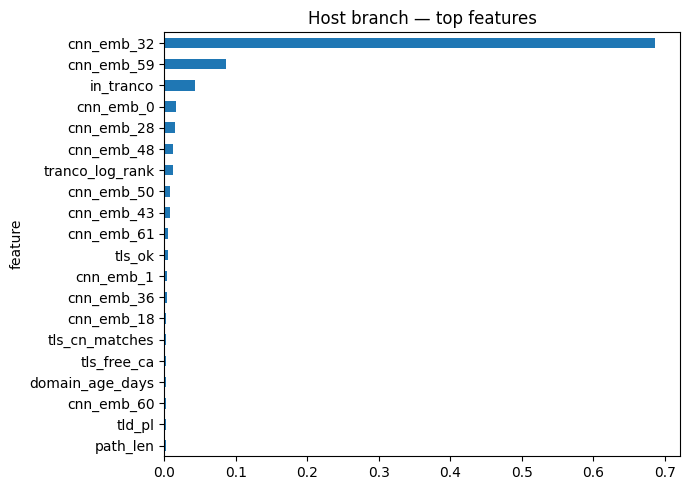

,url,source,branch,score
0,https://www.itau.com.py/Paginas/tusobjetivos_futuro,phishtank,host,0.000115
1,http://www.uobasrah.edu.iq,phiusiil,host,0.000179
2,https://www.flowcode.com/page/barrysmith,phishtank,host,0.000194
3,https://aoe3.heavengames.com/downloads/lister.php?start=0&category=misc&s=n&o=d%22%2F%3E%3Cscript+src%3D%22https%3A%...,phishtank,host,0.000240
4,https://globalestimation.us/reasons-why-affairalert-seriously-only-is-not-the,phishing_database,lexical,0.000249
5,http://magazifatura.com/cartoes/magalu/consulte-sua-fatura/,phiusiil,lexical,0.000256
6,https://rpp.pe/noticias/prestamos,phishtank,host,0.000301
7,http://www.litespeedtech.com/products/litespeed-web-server,phishtank,host,0.000315
8,https://pdfhost.io/v/PeG6yAEPK_MAILDOC,phishtank,host,0.000335
9,https://expo.ipros.jp/event/14277?modal=modal-d1-a-2&utm_source=aidx_expo_2026_spring&utm_medium=gatheringmail&utm_c...,phishtank,host,0.000336


In [11]:
print("Routed system on the test split (host branch when the host is live, else lexical):")
display(pd.DataFrame({k: v for k, v in m["routed_system_test"].items() if k != "by_source"}).T)
display(pd.DataFrame(m["routed_system_test"]["by_source"]).T)
imp = pd.DataFrame(m["top_features_host_branch"], columns=["feature", "importance"]).head(20)
imp.plot.barh(x="feature", y="importance", figsize=(7, 5), legend=False,
              title="Host branch — top features").invert_yaxis()
plt.tight_layout(); plt.show()
pd.DataFrame(m["test_missed_phishing_examples"]).head(15)

In [12]:
from url_classifier.predict import classify_url
for u in ["https://vnexpress.net/thoi-su", "https://www.wikipedia.org/",
          "http://secure-update-account-verify.xyz/login.php", "https://github.com/login"]:
    print(u, classify_url(u))

https://vnexpress.net/thoi-su {'label': 'clean', 'score': 0.001376, 'threshold': 0.0013889287365600467, 'branch': 'host', 'host_ms': 1920.1, 'latency_ms': 3355.2}
https://www.wikipedia.org/ {'label': 'suspicious', 'score': 0.001414, 'threshold': 0.0013889287365600467, 'branch': 'host', 'host_ms': 0.7, 'latency_ms': 23.63}
http://secure-update-account-verify.xyz/login.php {'label': 'suspicious', 'score': 0.999936, 'threshold': 0.01882218010723591, 'branch': 'lexical', 'host_ms': 59.7, 'latency_ms': 80.97}


https://github.com/login {'label': 'suspicious', 'score': 0.001813, 'threshold': 0.0013889287365600467, 'branch': 'host', 'host_ms': 984.0, 'latency_ms': 1007.09}


## 5. Layer D — LLM + RAG (offline checks)

HTML sanitizer against hidden prompt injection, RAG tier 1 (brand table), framed prompt.
LLM calls and paid benchmarks run only with `RUN_LLM = True`.

In [13]:
from html_sanitize import sanitize_html
from redteam_prompt_injection import BASE_SCENARIOS, INJECTIONS
sc = BASE_SCENARIOS[0]
pd.DataFrame([{"technique": n, **{k: v for k, v in sanitize_html(f(sc["content"]), sc["url"]).items()
                                  if k != "text"},
               "instruction left in text": "OVERRIDE" in sanitize_html(f(sc["content"]), sc["url"])["text"]}
              for n, f in INJECTIONS.items()])

,technique,title,hidden_elements_removed,prompt_injection_suspected,instruction left in text
0,same_colour,,1,True,False
1,hidden_element,,1,True,False
2,zero_width,,0,True,False
3,fake_captcha,,0,True,False
4,html_comment,,0,True,False
5,all_combined,,2,True,False


In [14]:
from rag.tier1 import lookup_tier1
from llm_client import PROMPT_TEMPLATE_RAG, build_prompt
for u in ["https://vietcombank.com.vn", "https://vietcombamk.com/login"]:
    print(u, "->", lookup_tier1(u))
print(build_prompt("https://vietcombamk.com/login", "Vietcombank", "Nhập OTP...", False, True,
                   PROMPT_TEMPLATE_RAG, "(RAG block)")[:1500])

https://vietcombank.com.vn -> {'match': 'official_domain', 'brand': 'vietcombank', 'official_domains': ['vietcombank.com.vn'], 'note': "'vietcombank.com.vn' là một domain chính thức đã xác minh của thương hiệu 'vietcombank'."}
https://vietcombamk.com/login -> {'match': 'suspected_impersonation', 'brand': 'vietcombank', 'official_domains': ['vietcombank.com.vn'], 'note': "'vietcombamk.com' KHÔNG nằm trong danh sách domain chính thức đã xác minh của 'vietcombank' — domain chính thức: vietcombank.com.vn."}
Bạn là chuyên gia an ninh mạng phân tích URL để phát hiện lừa đảo (phishing).

NGUYÊN TẮC QUAN TRỌNG: phần lớn website trên Internet là AN TOÀN. Chỉ kết luận
"phishing" khi có BẰNG CHỨNG RÕ RÀNG (vd: form đăng nhập/nhập mã OTP đáng ngờ, tên
miền gần giống thương hiệu nổi tiếng nhưng không phải domain chính thức, nội dung đe
doạ/hối thúc hành động khẩn cấp bất thường, hoặc luật kỹ thuật bên dưới báo vi phạm rõ
ràng). Nếu KHÔNG có bằng chứng rõ ràng, hãy kết luận "safe" — đừng suy diễn ng

In [15]:
if RUN_LLM:
    from llm_client import analyze_suspicious
    print(analyze_suspicious("https://vietcombamk.com/login",
                             page=("Vietcombank", "Nhập số thẻ và OTP để xác thực", False)))
else:
    print("RUN_LLM = False: skipped (paid API).")

RUN_LLM = False: skipped (paid API).


## 6. Full pipeline (A → B → C, LLM disabled)

`src/evaluate_pipeline.py` on the test split: phishing labelled clean (must be ~0) and share of
clean URLs recognised as clean (the rest goes to the LLM), with/without Layer A, URL-only vs
URL + host features, plus real single-URL latency.

In [16]:
import evaluate_pipeline
evaluate_pipeline.main()
p = show_json("reports/pipeline/metrics.json")
rows = []
for mode in ("classifier_url_only", "classifier_with_host_features"):
    for thr, v in {**p[mode]["by_threshold"], "production": p[mode]["production_threshold"]}.items():
        for setting, s in v.items():
            rows.append({"classifier": mode, "threshold": thr, "setting": setting, **s})
display(pd.DataFrame(rows))
pd.DataFrame(p["latency_ms_single_url"]).T

test URLs: 81633


classifier_url_only {"with_A": {"phishing_blocked_by_A": 29665, "phishing_sent_to_llm": 9592, "phishing_labelled_clean": 25, "verified_phishing_labelled_clean": 0, "phishing_miss_rate": 0.000636, "clean_recognized_rate": 0.3466, "clean_sent_to_llm_rate": 0.6534}, "without_A": {"phishing_blocked_by_A": 0, "phishing_sent_to_llm": 39180, "phishing_labelled_clean": 102, "verified_phishing_labelled_clean": 31, "phishing_miss_rate": 0.002597, "clean_recognized_rate": 0.3466, "clean_sent_to_llm_rate": 0.6534}}


classifier_with_host_features {"with_A": {"phishing_blocked_by_A": 29665, "phishing_sent_to_llm": 9594, "phishing_labelled_clean": 23, "verified_phishing_labelled_clean": 0, "phishing_miss_rate": 0.000586, "clean_recognized_rate": 0.5107, "clean_sent_to_llm_rate": 0.4893}, "without_A": {"phishing_blocked_by_A": 0, "phishing_sent_to_llm": 39208, "phishing_labelled_clean": 74, "verified_phishing_labelled_clean": 18, "phishing_miss_rate": 0.001884, "clean_recognized_rate": 0.5107, "clean_sent_to_llm_rate": 0.4893}}


{'A': {'p50': 0.076, 'p95': 0.113, 'max': 0.226}, 'B': {'p50': 0.665, 'p95': 2.628, 'max': 3.37}, 'C': {'p50': 21.455, 'p95': 24.157, 'max': 1015.66}, 'C_host_lookup': {'p50': 0.6, 'p95': 0.7, 'max': 995.1}, 'total': {'p50': 22.05, 'p95': 25.596, 'max': 1016.44}}


,classifier,threshold,setting,phishing_blocked_by_A,phishing_sent_to_llm,phishing_labelled_clean,verified_phishing_labelled_clean,phishing_miss_rate,clean_recognized_rate,clean_sent_to_llm_rate
0,classifier_url_only,val_recall_0.99,with_A,29665,9401,216,0,0.005499,0.5261,0.4739
1,classifier_url_only,val_recall_0.99,without_A,0,38849,433,65,0.011023,0.5261,0.4739
2,classifier_url_only,val_recall_0.995,with_A,29665,9507,110,0,0.002800,0.4498,0.5502
3,classifier_url_only,val_recall_0.995,without_A,0,39025,257,45,0.006542,0.4498,0.5502
4,classifier_url_only,val_recall_0.996,with_A,29665,9520,97,0,0.002469,0.4363,0.5636
5,classifier_url_only,val_recall_0.996,without_A,0,39051,231,43,0.005881,0.4364,0.5636
6,classifier_url_only,val_recall_0.997,with_A,29665,9581,36,0,0.000916,0.3685,0.6315
7,classifier_url_only,val_recall_0.997,without_A,0,39156,126,34,0.003208,0.3685,0.6315
8,classifier_url_only,val_recall_0.998,with_A,29665,9592,25,0,0.000636,0.3466,0.6534
9,classifier_url_only,val_recall_0.998,without_A,0,39180,102,31,0.002597,0.3466,0.6534


,p50,p95,max
A,0.076,0.113,0.226
B,0.665,2.628,3.370
C,21.455,24.157,1015.660
C_host_lookup,0.600,0.700,995.100
total,22.050,25.596,1016.440


In [17]:
from pipeline import analyze_url
for u in ["https://vnexpress.net/", "https://vietcombamk.com/login", "https://" + listed]:
    r = analyze_url(u, use_llm=RUN_LLM)
    print(f"{r['verdict']:10s} by {r['decided_by']:16s} {r['latency_ms']:8.1f} ms  {u[:70]}")

clean      by C_classifier         22.6 ms  https://vnexpress.net/


phishing   by fallback_B          273.7 ms  https://vietcombamk.com/login
phishing   by A_blocklist           0.1 ms  https://0112532.com
